# Classification

The following tutorial contains Python examples for solving classification problems. You should refer to the Chapters 3 and 4 of the "Introduction to Data Mining" book to understand some of the concepts introduced in this tutorial.

Classification is the task of predicting a nominal-valued attribute (known as class label) based on the values of other attributes (known as predictor variables). The goals for this tutorial are as follows:
1. To provide examples of using different classification techniques from the scikit-learn library package.
2. To demonstrate the problem of model overfitting.

Read the step-by-step instructions below carefully. To execute the code, click on the corresponding cell and press the SHIFT-ENTER keys simultaneously.


## 6.1 Vertebrate Dataset

We use a variation of the vertebrate data described in Example 3.1 of Chapter 3. Each vertebrate is classified into one of 5 categories: mammals, reptiles, birds, fishes, and amphibians, based on a set of explanatory attributes (predictor variables). Except for "name", the rest of the attributes have been converted into a *one hot encoding* binary representation. To illustrate this, we will first load the data into a Pandas DataFrame object and display its content.

In [70]:
import pandas as pd

# Solution notebooks are one directory below the shared data folder.
data = pd.read_csv('../data/vertebrate.csv',header='infer')
data

,Name,Warm-blooded,Gives Birth,Aquatic Creature,Aerial Creature,Has Legs,Hibernates,Class
0,human,1,1,0,0,1,0,mammals
1,python,0,0,0,0,0,1,reptiles
2,salmon,0,0,1,0,0,0,fishes
3,whale,1,1,1,0,0,0,mammals
4,frog,0,0,1,0,1,1,amphibians
5,komodo,0,0,0,0,1,0,reptiles
6,bat,1,1,0,1,1,1,mammals
7,pigeon,1,0,0,1,1,0,birds
8,cat,1,1,0,0,1,0,mammals
9,leopard shark,0,1,1,0,0,0,fishes


Given the limited number of training examples, suppose we convert the problem into a binary classification task (mammals versus non-mammals). We can do so by replacing the class labels of the instances to *non-mammals* except for those that belong to the *mammals* class.

In [71]:
data['Class'] = data['Class'].replace(['fishes','birds','amphibians','reptiles'],'non-mammals')
data

,Name,Warm-blooded,Gives Birth,Aquatic Creature,Aerial Creature,Has Legs,Hibernates,Class
0,human,1,1,0,0,1,0,mammals
1,python,0,0,0,0,0,1,non-mammals
2,salmon,0,0,1,0,0,0,non-mammals
3,whale,1,1,1,0,0,0,mammals
4,frog,0,0,1,0,1,1,non-mammals
5,komodo,0,0,0,0,1,0,non-mammals
6,bat,1,1,0,1,1,1,mammals
7,pigeon,1,0,0,1,1,0,non-mammals
8,cat,1,1,0,0,1,0,mammals
9,leopard shark,0,1,1,0,0,0,non-mammals


We can apply Pandas cross-tabulation to examine the relationship between the Warm-blooded and Gives Birth attributes with respect to the class. 

In [72]:
pd.crosstab([data['Warm-blooded'],data['Gives Birth']],data['Class'])

Class                     mammals  non-mammals
Warm-blooded Gives Birth                      
0            0                  0            7
             1                  0            1
1            0                  0            2
             1                  5            0

The results above show that it is possible to distinguish mammals from non-mammals using these two attributes alone since each combination of their attribute values would yield only instances that belong to the same class. For example, mammals can be identified as warm-blooded vertebrates that give birth to their young. Such a relationship can also be derived using a decision tree classifier, as shown by the example given in the next subsection.

## 3.2 Decision Tree Classifier

In this section, we apply a decision tree classifier to the vertebrate dataset described in the previous subsection.

In [73]:
from sklearn import tree

Y = data['Class']
X = data.drop(['Name','Class'],axis=1)

# Train the entropy-based decision tree.
clf = tree.DecisionTreeClassifier(criterion='entropy', max_depth=3)
clf = clf.fit(X, Y)

# Train a second decision tree using the Gini index.
clf_gini = tree.DecisionTreeClassifier(criterion='gini', max_depth=3)
clf_gini = clf_gini.fit(X, Y)

The preceding commands extract the predictor (X) and target class (Y) attributes from the vertebrate dataset and create two decision tree classifiers. The first uses entropy and the second uses the Gini index as its impurity measure. Both classifiers are constrained to a maximum depth of 3 and trained on the same labeled data using the `fit()` function. 

We can plot the entropy and Gini decision trees side by side using scikit-learn's built-in `plot_tree` function.

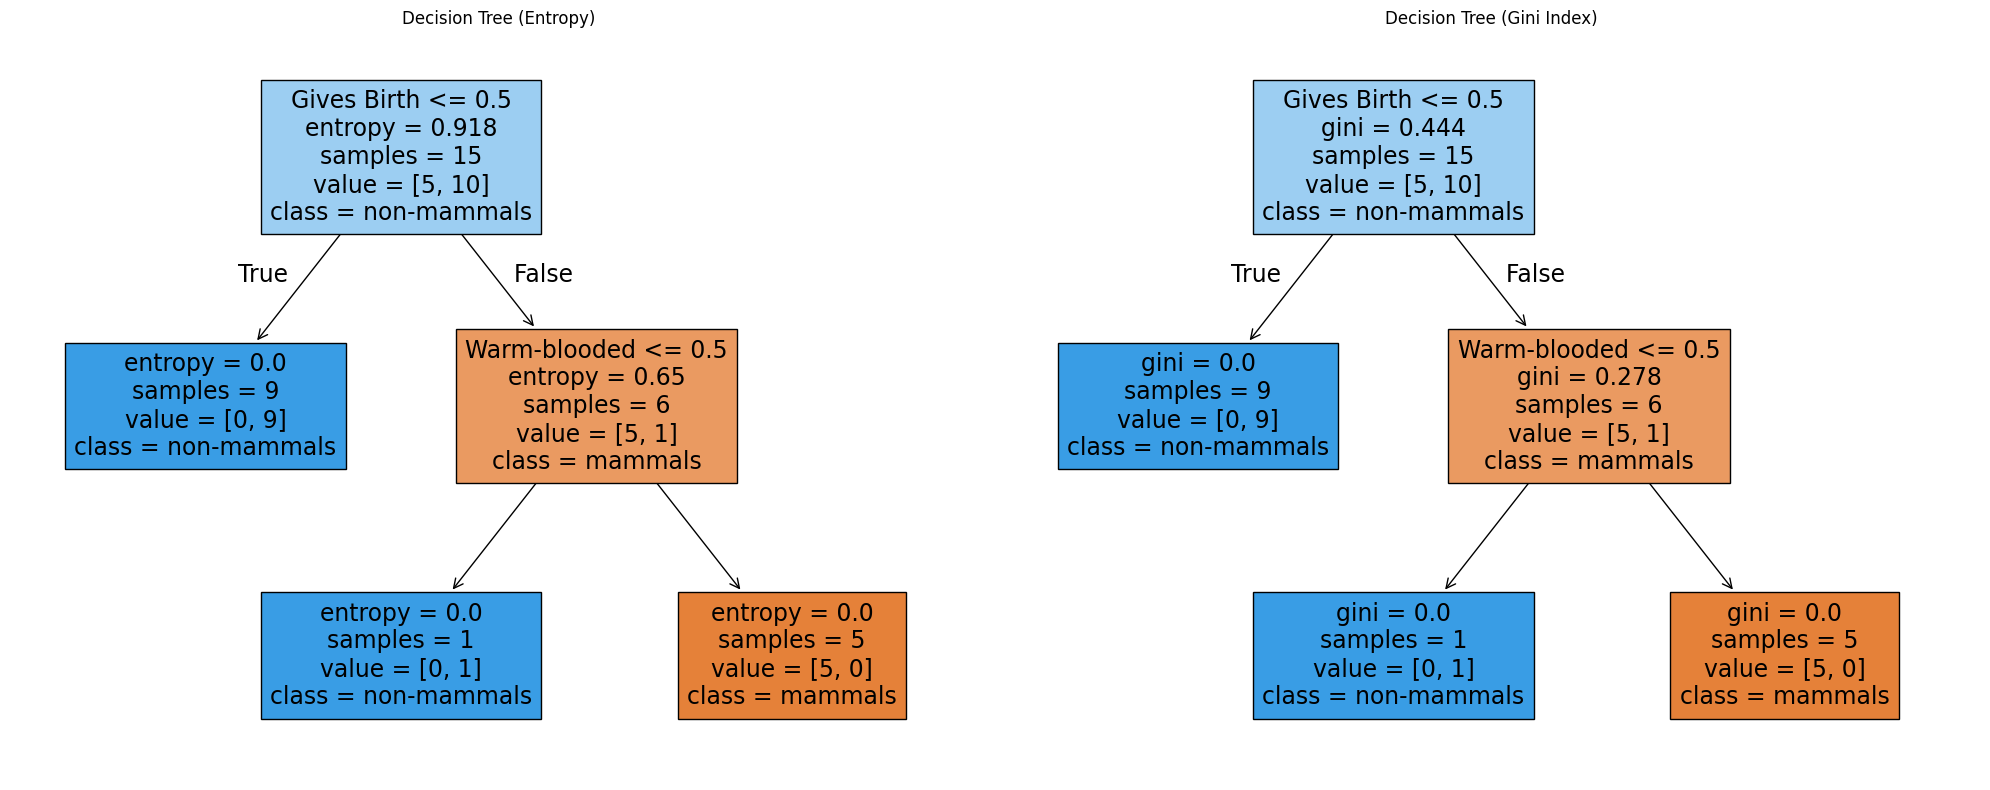

In [74]:
import matplotlib.pyplot as plt

# Render both fitted trees side by side for comparison.
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
tree.plot_tree(clf, feature_names=X.columns, class_names=clf.classes_, filled=True, ax=axes[0])
axes[0].set_title('Decision Tree (Entropy)')
tree.plot_tree(clf_gini, feature_names=X.columns, class_names=clf_gini.classes_, filled=True, ax=axes[1])
axes[1].set_title('Decision Tree (Gini Index)')
plt.tight_layout()
plt.show()

An entropy or Gini index of **0** means that the node is pure: every training example in that node belongs to the same class. Therefore, no uncertainty remains about the class label within that node. Larger values indicate a mixture of classes, although entropy and the Gini index use different scales to measure that impurity.

Next, suppose we apply the decision tree to classify the following test examples.

In [75]:
testData = [['gila monster',0,0,0,0,1,1,'non-mammals'],
           ['platypus',1,0,0,0,1,1,'mammals'],
           ['owl',1,0,0,1,1,0,'non-mammals'],
           ['dolphin',1,1,1,0,0,0,'mammals']]
testData = pd.DataFrame(testData, columns=data.columns)
testData

,Name,Warm-blooded,Gives Birth,Aquatic Creature,Aerial Creature,Has Legs,Hibernates,Class
0,gila monster,0,0,0,0,1,1,non-mammals
1,platypus,1,0,0,0,1,1,mammals
2,owl,1,0,0,1,1,0,non-mammals
3,dolphin,1,1,1,0,0,0,mammals


We first extract the predictor and target class attributes from the test data and then apply the decision tree classifier to predict their classes.

In [76]:
testY = testData['Class']
testX = testData.drop(['Name','Class'],axis=1)

predY = clf.predict(testX)
predictions = pd.concat([testData['Name'],pd.Series(predY,name='Predicted Class')], axis=1)
predictions

,Name,Predicted Class
0,gila monster,non-mammals
1,platypus,non-mammals
2,owl,non-mammals
3,dolphin,mammals


Except for platypus, which is an egg-laying mammal, the classifier correctly predicts the class label of the test examples. We can calculate the accuracy of the classifier on the test data as shown by the example given below.

In [77]:
from sklearn.metrics import accuracy_score

print('Accuracy on test data is %.2f' % (accuracy_score(testY, predY)))

Accuracy on test data is 0.75


## 3.3 Model Overfitting

To illustrate the problem of model overfitting, we consider a two-dimensional dataset containing 1500 labeled instances, each of which is assigned to one of two classes, 0 or 1. Instances from each class are generated as follows:
1. Instances from class 1 are generated from a mixture of 3 Gaussian distributions, centered at [6,14], [10,6], and [14 14], respectively. 
2. Instances from class 0 are generated from a uniform distribution in a square region, whose sides have a length equals to 20.

For simplicity, both classes have equal number of labeled instances. The code for generating and plotting the data is shown below. All instances from class 1 are shown in red while those from class 0 are shown in black.

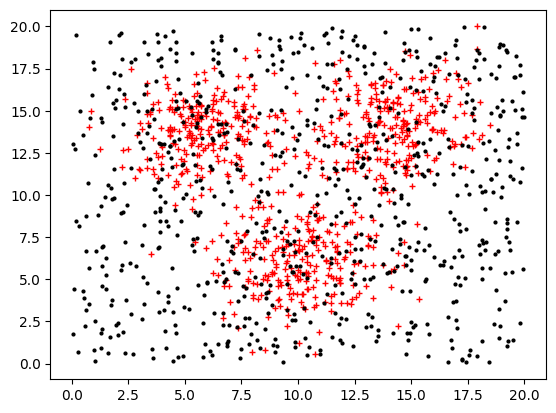

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.random import random

%matplotlib inline

# number of samples
N = 1500

mean1 = [6, 14]
mean2 = [10, 6]
mean3 = [14, 14]
cov = [[3.5, 0], [0, 3.5]]  # diagonal covariance (variance=3.5 per dim)

np.random.seed(50)

# --- create the Gaussian mixture (class 1) ---
# int(N/6) = 1500/6 = 250 samples per Gaussian
X = np.random.multivariate_normal(mean1, cov, int(N/6))                      # 250 samples from Gaussian centered at mean1
X = np.concatenate((X, np.random.multivariate_normal(mean2, cov, int(N/6)))) # +250 from Gaussian centered at mean2 -> 500 total
X = np.concatenate((X, np.random.multivariate_normal(mean3, cov, int(N/6)))) # +250 from Gaussian centered at mean3 -> 750 total

# --- create the uniform background (class 0) ---
# int(N/2) = 750 uniform samples in [0,20) for each coordinate
X = np.concatenate((X, 20*np.random.rand(int(N/2), 2)))                       # +750 uniform samples -> 1500 total

# Labels: first 750 are class 1, next 750 are class 0
Y = np.concatenate((np.ones(int(N/2)), np.zeros(int(N/2))))               

plt.plot(X[:int(N/2),0],X[:int(N/2),1],'r+',X[int(N/2):,0],X[int(N/2):,1],'k.',ms=4)

### Guided experiment: tree depth and overfitting

We reserve 20% of the labeled data for training and 80% for testing. The deliberately small training set makes overfitting easier to observe. Follow these steps:

1. Split the data with `test_size=0.8` and `random_state=1`.
2. Train decision trees with increasing maximum depths from 2 to 50.
3. Record both training and test accuracy at every depth.
4. Identify the depth with the highest test accuracy and inspect what happens beyond it.

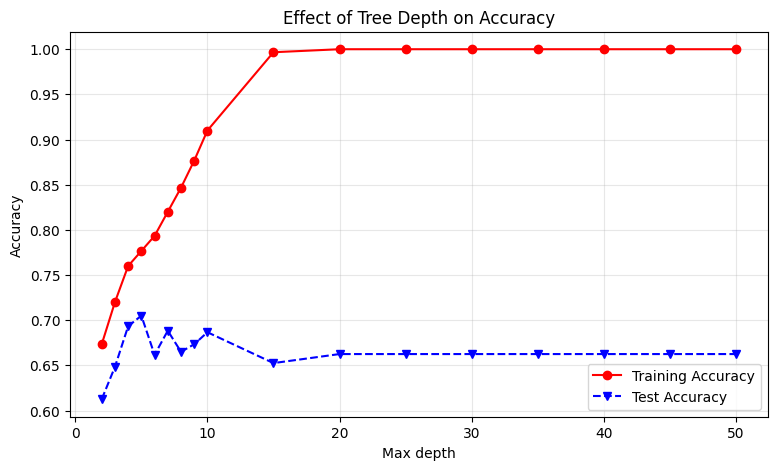

In [79]:
#########################################
# Training and Test set creation
#########################################

from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.8, random_state=1)

from sklearn import tree
from sklearn.metrics import accuracy_score

#########################################
# Model fitting and evaluation
#########################################

# Different max tree depths to try
maxdepths = [2,3,4,5,6,7,8,9,10,15,20,25,30,35,40,45,50]

trainAcc = np.zeros(len(maxdepths))
testAcc = np.zeros(len(maxdepths))

index = 0
for depth in maxdepths:
    # Keep the random state fixed so depth is the only changing factor.
    clf = tree.DecisionTreeClassifier(max_depth=depth, random_state=1)
    clf = clf.fit(X_train, Y_train)
    Y_predTrain = clf.predict(X_train)
    Y_predTest = clf.predict(X_test)
    trainAcc[index] = accuracy_score(Y_train, Y_predTrain)
    testAcc[index] = accuracy_score(Y_test, Y_predTest)
    index += 1
    
#########################################
# Plot of training and test accuracies
#########################################
    
plt.figure(figsize=(9, 5))
plt.plot(maxdepths,trainAcc,'ro-',maxdepths,testAcc,'bv--')
plt.legend(['Training Accuracy','Test Accuracy'])
plt.xlabel('Max depth')
plt.ylabel('Accuracy')
plt.title('Effect of Tree Depth on Accuracy')
plt.grid(alpha=0.3)
plt.show()

### Checkpoint 1: locate the onset of overfitting

Find the depth that gives the highest test accuracy. Then calculate the generalization gap, defined as `training accuracy - test accuracy`, for every depth. A growing positive gap means that the tree is fitting the training data increasingly well without improving on unseen data.

In [80]:
# Locate the model that performs best on unseen data.
best_index = np.argmax(testAcc)
best_depth = maxdepths[best_index]

# Measure how much better each tree performs on its training data.
generalization_gap = trainAcc - testAcc

print(f'Best test depth: {best_depth}')
print(f'Best test accuracy: {testAcc[best_index]:.3f}')
print(f'Training accuracy at that depth: {trainAcc[best_index]:.3f}')

Best test depth: 5
Best test accuracy: 0.705
Training accuracy at that depth: 0.777


### Checkpoint 2: make the divergence visible

The generalization gap below makes overfitting explicit. The dashed line marks the depth selected using test accuracy; a widening gap beyond it shows that additional depth mainly benefits the training set.

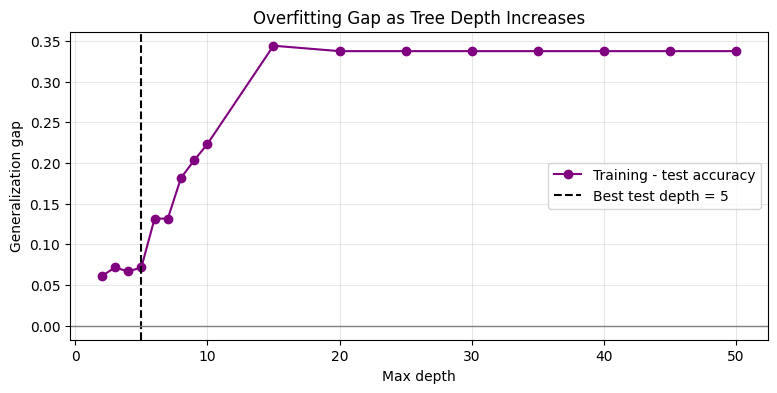

In [81]:
# Plot the difference between training and test performance.
plt.figure(figsize=(9, 4))
plt.plot(maxdepths, generalization_gap, 'o-', color='purple', label='Training - test accuracy')
plt.axvline(best_depth, color='black', linestyle='--', label=f'Best test depth = {best_depth}')
plt.axhline(0, color='gray', linewidth=1)
plt.xlabel('Max depth')
plt.ylabel('Generalization gap')
plt.title('Overfitting Gap as Tree Depth Increases')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Checkpoint 3: compare representative depths

Compare a shallow tree, the tree selected by test accuracy, and the deepest tree. Notice that the deepest tree can have the best training score while producing a worse test score and a larger gap.

In [82]:
# Summarize representative models without retraining them.
comparison_indices = [0, best_index, len(maxdepths) - 1]
print('Depth | Train accuracy | Test accuracy | Gap')
print('-' * 47)
for index in comparison_indices:
    print(
        f'{maxdepths[index]:>5} | {trainAcc[index]:>14.3f} | '
        f'{testAcc[index]:>13.3f} | {generalization_gap[index]:>5.3f}'
    )

Depth | Train accuracy | Test accuracy | Gap
-----------------------------------------------
    2 |          0.673 |         0.613 | 0.061
    5 |          0.777 |         0.705 | 0.072
   50 |          1.000 |         0.662 | 0.338


As depth increases, the tree gains enough flexibility to reproduce increasingly specific patterns—and eventually noise—from the training set. Training accuracy therefore keeps increasing or remains very high. Test accuracy improves only while the additional complexity captures patterns that generalize; after the best depth, it stagnates or decreases while the generalization gap widens. This divergence is the evidence of overfitting. Choosing the model with the highest training accuracy would therefore favor an unnecessarily deep tree rather than the model that generalizes best.

## 3.4 Alternative Classification Techniques

Besides decision tree classifier, the Python sklearn library also supports other classification techniques. In this section, we provide examples to illustrate how to apply the k-nearest neighbor classifier, linear classifiers (logistic regression and support vector machine), as well as ensemble methods (boosting, bagging, and random forest) to the 2-dimensional data given in the previous section.

### 3.4.1 K-Nearest neighbor classifier

In this approach, the class label of a test instance is predicted based on the majority class of its *k* closest training instances. The number of nearest neighbors, *k*, is a hyperparameter that must be provided by the user, along with the distance metric. By default, we can use Euclidean distance (which is equivalent to Minkowski distance with an exponent factor equals to p=2):

\begin{equation*}
\textrm{Minkowski distance}(x,y) = \bigg[\sum_{i=1}^N |x_i-y_i|^p \bigg]^{\frac{1}{p}}
\end{equation*}

#### Intuition: classify by asking the nearest examples

The schematic below uses $k=5$. The outlined points are the five training examples closest to the new, unlabelled point. KNN assigns the class that occurs most often among those neighbors.

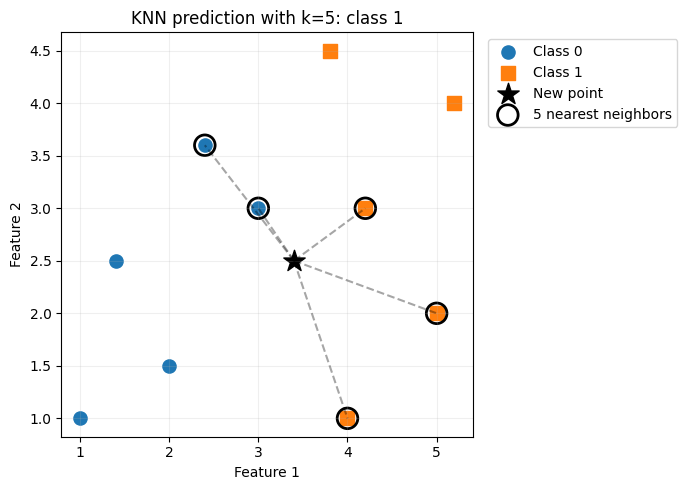

In [83]:
import numpy as np
import matplotlib.pyplot as plt

# Create a small, deterministic dataset for the KNN schematic.
class_0 = np.array([[1, 1], [2, 1.5], [1.4, 2.5], [3, 3], [2.4, 3.6]])
class_1 = np.array([[4, 1], [5, 2], [4.2, 3], [5.2, 4], [3.8, 4.5]])
training_points = np.vstack([class_0, class_1])
training_labels = np.array([0] * len(class_0) + [1] * len(class_1))
query_point = np.array([3.4, 2.5])
k = 5

# Find the k closest points using Euclidean distance.
distances = np.linalg.norm(training_points - query_point, axis=1)
neighbor_indices = np.argsort(distances)[:k]
predicted_class = np.bincount(training_labels[neighbor_indices]).argmax()

# Plot the observations, query point, and selected neighborhood.
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(class_0[:, 0], class_0[:, 1], marker='o', s=90, label='Class 0')
ax.scatter(class_1[:, 0], class_1[:, 1], marker='s', s=90, label='Class 1')
ax.scatter(*query_point, marker='*', s=260, color='black', label='New point')
ax.scatter(training_points[neighbor_indices, 0], training_points[neighbor_indices, 1],
           s=220, facecolors='none', edgecolors='black', linewidths=2, label=f'{k} nearest neighbors')
for index in neighbor_indices:
    ax.plot([query_point[0], training_points[index, 0]],
            [query_point[1], training_points[index, 1]], 'k--', alpha=0.35)
ax.set_title(f'KNN prediction with k={k}: class {predicted_class}')
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

KNN does not learn a formula or a tree during training; it stores the labelled examples. To classify a new point, it (1) measures its distance to the training points, (2) selects the $k$ closest ones, and (3) uses their majority class. Small $k$ values create flexible, noise-sensitive boundaries, while larger $k$ values produce smoother boundaries but may hide local patterns. Feature scaling matters because a feature with a large numerical range can dominate the distance.

Text(0, 0.5, 'Accuracy')

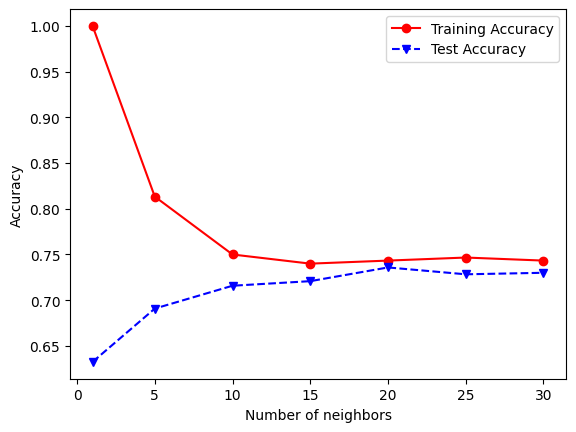

In [84]:
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
%matplotlib inline

numNeighbors = [1, 5, 10, 15, 20, 25, 30]
trainAcc = []
testAcc = []

for k in numNeighbors:
    clf = KNeighborsClassifier(n_neighbors=k, metric='minkowski', p=2) # minkowski # euclidean # manhattan
    clf.fit(X_train, Y_train)
    Y_predTrain = clf.predict(X_train)
    Y_predTest = clf.predict(X_test)
    trainAcc.append(accuracy_score(Y_train, Y_predTrain))
    testAcc.append(accuracy_score(Y_test, Y_predTest))

plt.plot(numNeighbors, trainAcc, 'ro-', numNeighbors, testAcc,'bv--')
plt.legend(['Training Accuracy','Test Accuracy'])
plt.xlabel('Number of neighbors')
plt.ylabel('Accuracy')

### 3.4.2 Linear Classifiers

Linear classifiers such as logistic regression construct a linear separating hyperplane to distinguish instances from different classes. 

For logistic regression, the model can be described by the following equation:
\begin{equation*}
P(y=1|x) = \frac{1}{1 + \exp^{-w^Tx - b}} = \sigma(w^Tx + b)
\end{equation*}
The model parameters (w,b) are estimated by optimizing the following regularized negative log-likelihood function:
\begin{equation*}
(w^*,b^*) = \arg\min_{w,b} - \sum_{i=1}^N y_i \log\bigg[\sigma(w^Tx_i + b)\bigg] + (1-y_i) \log\bigg[\sigma(-w^Tx_i - b)\bigg] + \frac{1}{C} \Omega([w,b])
\end{equation*}
where $C$ is a hyperparameter that controls the inverse of model complexity (smaller values imply stronger regularization, it controls how strongly the model is penalized for large weights) while $\Omega(\cdot)$ is the regularization term, which by default, is assumed to be an $l_2$-norm in sklearn.

#### Intuition: a linear score becomes a probability

Logistic regression first computes a weighted score $z=w^Tx+b$. The sigmoid transforms that score into a probability between 0 and 1. For binary classification, the usual threshold is $P(y=1|x)=0.5$, which corresponds to $z=0$ and defines a linear decision boundary.

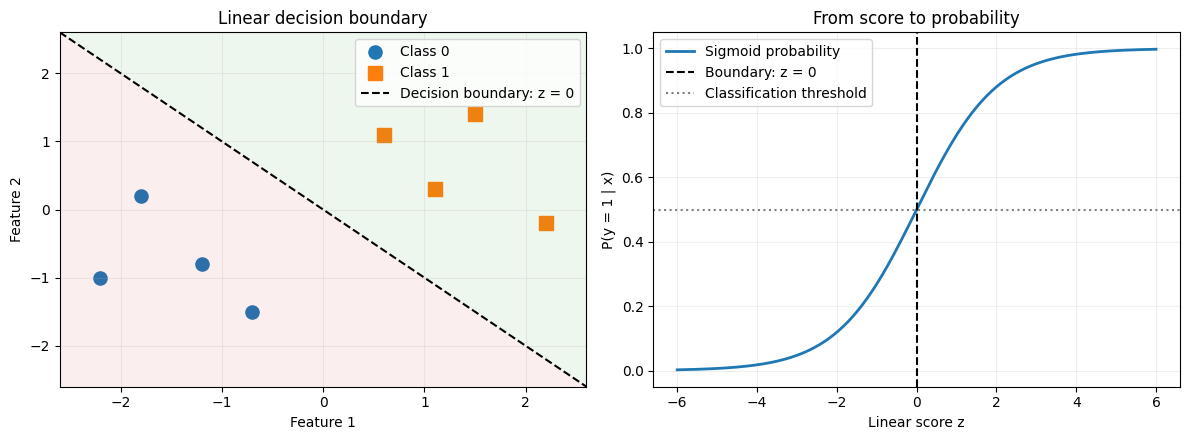

In [85]:
import numpy as np
import matplotlib.pyplot as plt

# Create a simple two-class example separated by the line x1 + x2 = 0.
class_0_lr = np.array([[-2.2, -1.0], [-1.8, 0.2], [-1.2, -0.8], [-0.7, -1.5]])
class_1_lr = np.array([[0.6, 1.1], [1.1, 0.3], [1.5, 1.4], [2.2, -0.2]])
boundary_x = np.linspace(-2.6, 2.6, 200)
scores = np.linspace(-6, 6, 300)
probabilities = 1 / (1 + np.exp(-scores))

# Show the geometric boundary and the sigmoid probability mapping.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(class_0_lr[:, 0], class_0_lr[:, 1], marker='o', s=90, label='Class 0')
axes[0].scatter(class_1_lr[:, 0], class_1_lr[:, 1], marker='s', s=90, label='Class 1')
axes[0].plot(boundary_x, -boundary_x, 'k--', label='Decision boundary: z = 0')
axes[0].fill_between(boundary_x, -boundary_x, 3, alpha=0.08)
axes[0].fill_between(boundary_x, -3, -boundary_x, alpha=0.08)
axes[0].set(xlim=(-2.6, 2.6), ylim=(-2.6, 2.6), xlabel='Feature 1', ylabel='Feature 2',
            title='Linear decision boundary')
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(scores, probabilities, linewidth=2, label='Sigmoid probability')
axes[1].axvline(0, color='black', linestyle='--', label='Boundary: z = 0')
axes[1].axhline(0.5, color='gray', linestyle=':', label='Classification threshold')
axes[1].set(xlabel='Linear score z', ylabel='P(y = 1 | x)',
            title='From score to probability', ylim=(-0.05, 1.05))
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

Points on one side of the boundary have probabilities below 0.5 and are assigned to class 0; points on the other side have probabilities above 0.5 and are assigned to class 1. The farther a point is from the boundary in the direction of $w$, the more confident the prediction becomes. The parameter $C$ controls regularization: smaller $C$ values penalize large weights more strongly, usually producing a simpler and less extreme model.

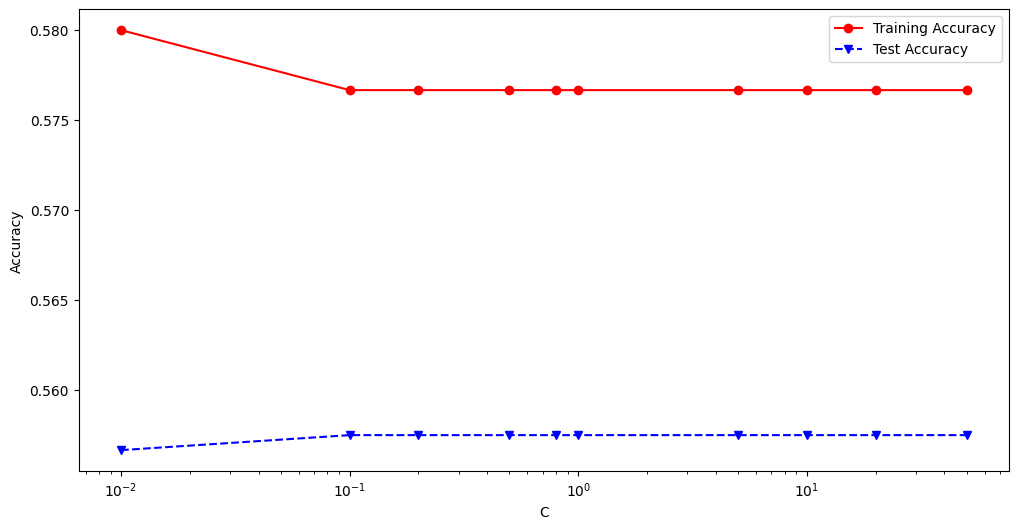

Threshold | Accuracy | TN | FP | FN | TP | Predicted class 1
--------------------------------------------------------------------
      0.3 |    0.503 |  0 | 596 |  0 | 604 |             1.000
      0.5 |    0.557 | 341 | 255 | 276 | 328 |             0.486
      0.7 |    0.497 | 596 |  0 | 604 |  0 |             0.000


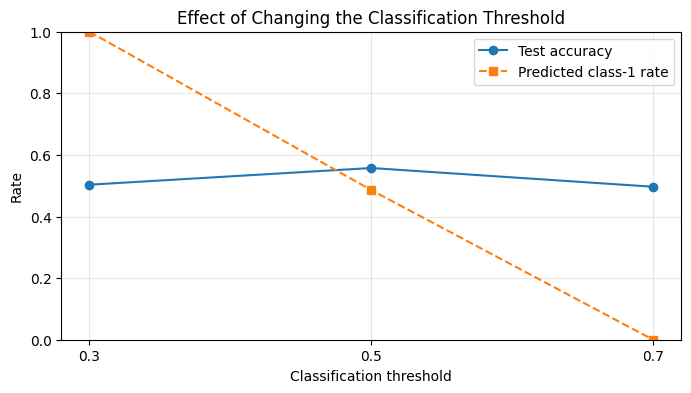

In [88]:
from sklearn import linear_model
import warnings
warnings.filterwarnings('ignore')


C = [0.01, 0.1, 0.2, 0.5, 0.8, 1, 5, 10, 20, 50]
LRtrainAcc = []
LRtestAcc = []

for param in C:
    clf = linear_model.LogisticRegression(C=param)
    clf.fit(X_train, Y_train)
    Y_predTrain = clf.predict(X_train)
    Y_predTest = clf.predict(X_test)
    LRtrainAcc.append(accuracy_score(Y_train, Y_predTrain))
    LRtestAcc.append(accuracy_score(Y_test, Y_predTest))

fig, ax = plt.subplots(figsize=(12,6))
ax.plot(C, LRtrainAcc, 'ro-', C, LRtestAcc, 'bv--')
ax.legend(['Training Accuracy','Test Accuracy'])
ax.set_xlabel('C')
ax.set_xscale('log')
ax.set_ylabel('Accuracy')
plt.show()

#########################################
# Classification-threshold experiment
#########################################

from sklearn.metrics import confusion_matrix

# Fit one model; changing the threshold does not retrain it.
threshold_model = linear_model.LogisticRegression(C=1, random_state=1)
threshold_model.fit(X_train, Y_train)
class_1_probabilities = threshold_model.predict_proba(X_test)[:, 1]
thresholds = [0.3, 0.5, 0.7]
threshold_accuracies = []
predicted_positive_rates = []

print('Threshold | Accuracy | TN | FP | FN | TP | Predicted class 1')
print('-' * 68)
for threshold in thresholds:
    # Apply a custom threshold to the same predicted probabilities.
    threshold_predictions = (class_1_probabilities >= threshold).astype(int)
    threshold_accuracy = accuracy_score(Y_test, threshold_predictions)
    tn, fp, fn, tp = confusion_matrix(Y_test, threshold_predictions, labels=[0, 1]).ravel()
    positive_rate = threshold_predictions.mean()
    threshold_accuracies.append(threshold_accuracy)
    predicted_positive_rates.append(positive_rate)
    print(f'{threshold:>9.1f} | {threshold_accuracy:>8.3f} | {tn:>2} | {fp:>2} | {fn:>2} | {tp:>2} | {positive_rate:>17.3f}')

# Compare overall accuracy with how often the model predicts class 1.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, threshold_accuracies, 'o-', label='Test accuracy')
ax.plot(thresholds, predicted_positive_rates, 's--', label='Predicted class-1 rate')
ax.set_xlabel('Classification threshold')
ax.set_ylabel('Rate')
ax.set_title('Effect of Changing the Classification Threshold')
ax.set_xticks(thresholds)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

The default logistic-regression threshold is 0.5. Lowering it predicts class 1 more often, which generally reduces false negatives but increases false positives. Raising it predicts class 1 less often, generally reducing false positives but increasing false negatives. The model and its probabilities do not change—only the rule that converts probabilities into labels changes. Accuracy alone may hide this trade-off, so inspect the confusion-matrix counts as well. Note also that this linear classifier performs poorly on the dataset because the true decision boundary is nonlinear.

### 3.4.4 Ensemble Methods

An ensemble classifier constructs a set of base classifiers from the training data and performs classification by taking a vote on the predictions made by each base classifier. We consider 3 types of ensemble classifiers in this example: bagging, boosting, and random forest. Detailed explanation about these classifiers can be found in Section 4.10 of the book.

In the example below, we fit 500 base classifiers to the 2-dimensional dataset using each ensemble method. The base classifier corresponds to a decision tree with maximum depth equals to 10.

Text(0.5, 1.0, 'Test Accuracy')

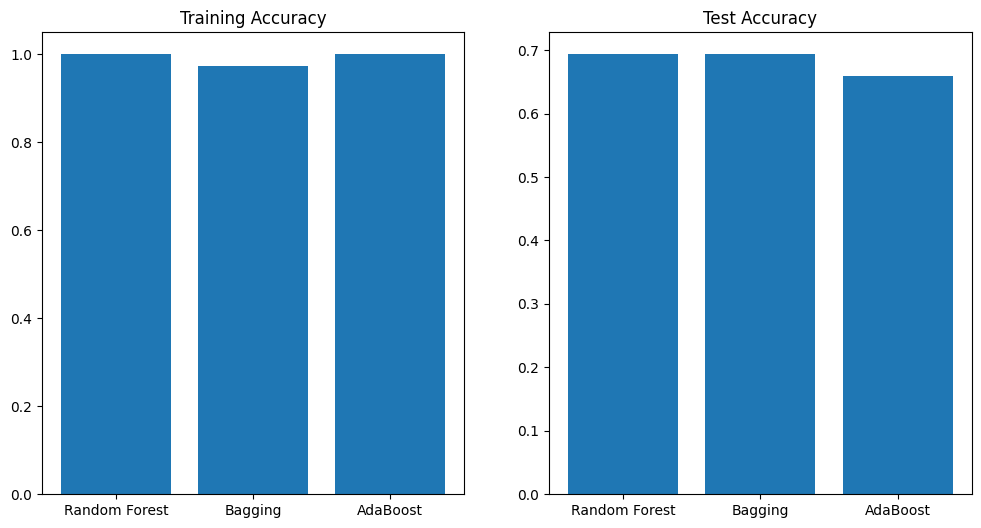

In [87]:
from sklearn import ensemble
from sklearn.tree import DecisionTreeClassifier

numBaseClassifiers = 500
maxdepth = 10
trainAcc = []
testAcc = []

clf = ensemble.RandomForestClassifier(n_estimators=numBaseClassifiers)
clf.fit(X_train, Y_train)
Y_predTrain = clf.predict(X_train)
Y_predTest = clf.predict(X_test)
trainAcc.append(accuracy_score(Y_train, Y_predTrain))
testAcc.append(accuracy_score(Y_test, Y_predTest))

clf = ensemble.BaggingClassifier(DecisionTreeClassifier(max_depth=maxdepth),n_estimators=numBaseClassifiers)
clf.fit(X_train, Y_train)
Y_predTrain = clf.predict(X_train)
Y_predTest = clf.predict(X_test)
trainAcc.append(accuracy_score(Y_train, Y_predTrain))
testAcc.append(accuracy_score(Y_test, Y_predTest))

clf = ensemble.AdaBoostClassifier(DecisionTreeClassifier(max_depth=maxdepth),n_estimators=numBaseClassifiers)
clf.fit(X_train, Y_train)
Y_predTrain = clf.predict(X_train)
Y_predTest = clf.predict(X_test)
trainAcc.append(accuracy_score(Y_train, Y_predTrain))
testAcc.append(accuracy_score(Y_test, Y_predTest))

methods = ['Random Forest', 'Bagging', 'AdaBoost']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,6))
ax1.bar([1.5,2.5,3.5], trainAcc)
ax1.set_xticks([1.5,2.5,3.5])
ax1.set_xticklabels(methods)
ax1.set_title('Training Accuracy')
ax2.bar([1.5,2.5,3.5], testAcc)
ax2.set_xticks([1.5,2.5,3.5])
ax2.set_xticklabels(methods)
ax2.set_title('Test Accuracy')

## 3.5 Summary

This section provides several examples of using Python sklearn library to build classification models from a given input data. We also illustrate the problem of model overfitting and show how to apply different classification methods to the given dataset.